# FoodOps AI — Previsão de atrasos de entregas

**Projeto de portfólio | Python · Pandas · Scikit-learn · XGBoost · Power BI**

 Disponibilize o arquivo Olist no caminho usado no código (`/content/archive (2).zip`) ou ajuste apenas o caminho de entrada conforme o ambiente.

> **Escopo:** estudo retrospectivo de pedidos entregues. O risco previsto é adequado à **ordenação relativa** dos pedidos; a calibração das probabilidades não foi resolvida.

**O que faremos e por quê:** Apresentar o problema de negócio: identificar pedidos com maior risco de atraso para priorizar o acompanhamento logístico.

## 1. Introdução e objetivo

**Problema:** uma operação de e-commerce não consegue acompanhar todos os pedidos com a mesma intensidade. O FoodOps AI utiliza dados de compras, vendedores, frete e prazo prometido para ordenar os pedidos por risco de atraso.

**Pergunta central:** ao acompanhar os 10% de pedidos com maior risco previsto, quantos atrasos conseguimos identificar?

**Momento da previsão proposto:** compra do pedido. Os atributos precisam estar disponíveis nesse instante; a disponibilidade histórica de todas as informações não pôde ser demonstrada integralmente.

**O que faremos e por quê:** Carregar as tabelas Olist e verificar datas, valores ausentes, status e duplicidades antes de construir o modelo.

## 2. Carregamento e qualidade dos dados

In [4]:
from pathlib import Path

# Localizar o ZIP da Olist no ambiente do Colab.
arquivos_zip = sorted(Path("/content").glob("*.zip"))
if len(arquivos_zip) == 1:
    caminho_zip = str(arquivos_zip[0])
elif len(arquivos_zip) == 0:
    from google.colab import files
    enviados = files.upload()
    arquivos_zip = [nome for nome in enviados if nome.lower().endswith(".zip")]
    if len(arquivos_zip) != 1:
        raise ValueError("Envie exatamente um arquivo ZIP com os dados Olist.")
    caminho_zip = arquivos_zip[0]
else:
    raise ValueError("Há mais de um ZIP em /content. Defina caminho_zip manualmente para o arquivo Olist.")

print("Arquivo de dados:", caminho_zip)


Arquivo de dados: /content/archive (2).zip


In [5]:
import pandas as pd
import zipfile

with zipfile.ZipFile(caminho_zip) as zip_ref:
    with zip_ref.open("olist_orders_dataset.csv") as arquivo:
        df = pd.read_csv(arquivo)

print(df.shape)
display(df.head())

(99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
# Visualizar os nomes das colunas
print(df.columns.tolist())

# Verificar tipos de dados e valores não nulos
df.info()

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [7]:

# Identificar as colunas que representam datas
colunas_datas = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Converter para o formato datetime
for coluna in colunas_datas:
    df[coluna] = pd.to_datetime(df[coluna], errors="coerce")

# Conferir os novos tipos
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [8]:

# Quantidade de valores ausentes por coluna
valores_nulos = df.isnull().sum()

# Porcentagem de valores ausentes
percentual_nulos = (valores_nulos / len(df)) * 100

# Criar tabela de qualidade dos dados
qualidade_dados = pd.DataFrame({
    "Valores Ausentes": valores_nulos,
    "Percentual (%)": percentual_nulos.round(2)
})

display(qualidade_dados)


,Valores Ausentes,Percentual (%)
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


In [9]:

# Contagem de pedidos por status
status_pedidos = df["order_status"].value_counts()

# Percentual de cada status
percentual_status = (
    df["order_status"]
    .value_counts(normalize=True) * 100
).round(2)

# Criar tabela
analise_status = pd.DataFrame({
    "Quantidade": status_pedidos,
    "Percentual (%)": percentual_status
})

display(analise_status)



,Quantidade,Percentual (%)
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


In [10]:

# Verificar datas de entrega ausentes por status
analise_entregas = pd.crosstab(
    df["order_status"],
    df["order_delivered_customer_date"].isna()
)

# Renomear colunas
analise_entregas = analise_entregas.rename(
    columns={
        False: "Com data de entrega",
        True: "Sem data de entrega"
    }
)

display(analise_entregas)


order_delivered_customer_date,Com data de entrega,Sem data de entrega
order_status,,
approved,0,2
canceled,6,619
created,0,5
delivered,96470,8
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


In [11]:

# Selecionar pedidos entregues com data registrada
entregas_validacao = df[
    (df["order_status"] == "delivered") &
    (df["order_delivered_customer_date"].notna())
].copy()

# Verificar entregas anteriores à compra
datas_inconsistentes = (
    entregas_validacao["order_delivered_customer_date"] <
    entregas_validacao["order_purchase_timestamp"]
)

print("Pedidos para validação:", len(entregas_validacao))
print("Entregas anteriores à compra:", datas_inconsistentes.sum())


Pedidos para validação: 96470
Entregas anteriores à compra: 0


In [12]:

# Verificar prazos estimados anteriores à compra
prazos_inconsistentes = (
    entregas_validacao["order_estimated_delivery_date"] <
    entregas_validacao["order_purchase_timestamp"]
)

print("Pedidos analisados:", len(entregas_validacao))
print("Prazos estimados anteriores à compra:",
      prazos_inconsistentes.sum())


Pedidos analisados: 96470
Prazos estimados anteriores à compra: 0


In [13]:

# Verificar pedidos duplicados
duplicados = entregas_validacao["order_id"].duplicated().sum()

print("Total de pedidos:", len(entregas_validacao))
print("Pedidos duplicados:", duplicados)
print("Pedidos únicos:",
      entregas_validacao["order_id"].nunique())


Total de pedidos: 96470
Pedidos duplicados: 0
Pedidos únicos: 96470


In [14]:

# Carregar a tabela de clientes
with zipfile.ZipFile(caminho_zip) as zip_ref:
    with zip_ref.open("olist_customers_dataset.csv") as arquivo:
        df_clientes = pd.read_csv(arquivo)

# Verificar dimensões
print("Dimensão:", df_clientes.shape)

# Visualizar os primeiros registros
display(df_clientes.head())

# Verificar estrutura
df_clientes.info()


Dimensão: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [15]:

# Verificar duplicações na chave customer_id
duplicados_clientes = df_clientes["customer_id"].duplicated().sum()

# Contar clientes únicos
clientes_unicos = df_clientes["customer_id"].nunique()

print("Total de registros:", len(df_clientes))
print("customer_id duplicados:", duplicados_clientes)
print("customer_id únicos:", clientes_unicos)


Total de registros: 99441
customer_id duplicados: 0
customer_id únicos: 99441


In [16]:

# Carregar a tabela de vendedores
with zipfile.ZipFile(caminho_zip) as zip_ref:
    with zip_ref.open("olist_sellers_dataset.csv") as arquivo:
        df_vendedores = pd.read_csv(arquivo)

# Verificar as dimensões
print("Dimensão:", df_vendedores.shape)

# Visualizar os primeiros registros
display(df_vendedores.head())

# Verificar a estrutura
df_vendedores.info()


Dimensão: (3095, 4)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [17]:

# Verificar duplicações na tabela de vendedores
duplicados_vendedores = (
    df_vendedores["seller_id"].duplicated().sum()
)

# Contar vendedores únicos
vendedores_unicos = df_vendedores["seller_id"].nunique()

print("Total de registros:", len(df_vendedores))
print("Vendedores duplicados:", duplicados_vendedores)
print("Vendedores únicos:", vendedores_unicos)


Total de registros: 3095
Vendedores duplicados: 0
Vendedores únicos: 3095


In [18]:

# Carregar a tabela de itens dos pedidos
with zipfile.ZipFile(caminho_zip) as zip_ref:
    with zip_ref.open("olist_order_items_dataset.csv") as arquivo:
        df_itens = pd.read_csv(arquivo)

# Verificar as dimensões
print("Dimensão:", df_itens.shape)

# Visualizar os primeiros registros
display(df_itens.head())

# Verificar tipos e valores ausentes
df_itens.info()


Dimensão: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [19]:

# Contar quantas linhas de itens existem por pedido
itens_por_pedido = (
    df_itens.groupby("order_id")
    .size()
)

# Verificar quantidade de pedidos únicos
print("Pedidos únicos:", df_itens["order_id"].nunique())

# Verificar maior quantidade de itens em um pedido
print("Máximo de itens em um pedido:", itens_por_pedido.max())

# Contar pedidos com um único item
print("Pedidos com 1 item:", (itens_por_pedido == 1).sum())

# Contar pedidos com múltiplos itens
print("Pedidos com mais de 1 item:", (itens_por_pedido > 1).sum())


Pedidos únicos: 98666
Máximo de itens em um pedido: 21
Pedidos com 1 item: 88863
Pedidos com mais de 1 item: 9803


**Interpretação dos resultados.** O recorte analítico utiliza pedidos com status de entrega e data de recebimento registrados. Essa escolha facilita a avaliação retrospectiva, mas exclui pedidos cancelados ou não entregues.

**O que faremos e por quê:** Definir atraso comparando a data efetiva de entrega com a data prometida, sem confundir horários com dias de atraso.

## 3. Construção da variável-alvo

In [20]:
# Criar uma cópia dos pedidos entregues para modelagem
df_modelo = entregas_validacao.copy()

In [21]:

# Comparar apenas as datas, ignorando os horários
df_modelo["atraso"] = (
    df_modelo["order_delivered_customer_date"].dt.normalize() >
    df_modelo["order_estimated_delivery_date"].dt.normalize()
).astype(int)

# Verificar a nova distribuição
print("Pedidos sem atraso:", (df_modelo["atraso"] == 0).sum())
print("Pedidos com atraso:", (df_modelo["atraso"] == 1).sum())

print("\nPercentual por classe:")
print(
    df_modelo["atraso"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Pedidos sem atraso: 89936
Pedidos com atraso: 6534

Percentual por classe:
atraso
0    93.23
1     6.77
Name: proportion, dtype: float64


**Interpretação dos resultados.** A variável `atraso` vale 1 quando o **dia** da entrega é posterior ao dia prometido, e 0 nos demais casos. Comparar timestamps completos criaria falsos atrasos porque o prazo estimado pode estar registrado à meia-noite.

**O que faremos e por quê:** Integrar informações de clientes, itens e vendedores e criar indicadores que possam ajudar a prever atrasos.

## 4. Engenharia de atributos

In [22]:

# Integrar pedidos com informações dos clientes
df_modelo_clientes = df_modelo.merge(
    df_clientes,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Conferir dimensões
print("Antes da integração:", df_modelo.shape)
print("Depois da integração:", df_modelo_clientes.shape)

# Verificar informações geográficas ausentes
print(
    "Estados ausentes:",
    df_modelo_clientes["customer_state"].isna().sum()
)

# Visualizar resultado
display(df_modelo_clientes.head())


Antes da integração: (96470, 9)
Depois da integração: (96470, 13)
Estados ausentes: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,atraso,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,0,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,0,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,0,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [23]:

# Agregar informações dos itens por pedido
df_itens_agrupados = (
    df_itens.groupby("order_id")
    .agg(
        quantidade_itens=("order_item_id", "count"),
        valor_produtos=("price", "sum"),
        valor_frete=("freight_value", "sum"),
        quantidade_vendedores=("seller_id", "nunique")
    )
    .reset_index()
)

# Verificar o resultado
print("Dimensão:", df_itens_agrupados.shape)

# Verificar duplicações
print(
    "Pedidos duplicados:",
    df_itens_agrupados["order_id"].duplicated().sum()
)

display(df_itens_agrupados.head())


Dimensão: (98666, 5)
Pedidos duplicados: 0


,order_id,quantidade_itens,valor_produtos,valor_frete,quantidade_vendedores
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,1
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,1
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,1
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,1


In [24]:

# Integrar informações dos itens à base principal
df_modelo_completo = df_modelo_clientes.merge(
    df_itens_agrupados,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Verificar dimensões
print("Antes:", df_modelo_clientes.shape)
print("Depois:", df_modelo_completo.shape)

# Verificar pedidos sem informações dos itens
print(
    "Pedidos sem itens:",
    df_modelo_completo["quantidade_itens"].isna().sum()
)

# Verificar duplicações
print(
    "Pedidos duplicados:",
    df_modelo_completo["order_id"].duplicated().sum()
)


Antes: (96470, 13)
Depois: (96470, 17)
Pedidos sem itens: 0
Pedidos duplicados: 0


In [25]:

# Criar categorias de quantidade de itens
df_modelo_completo["categoria_itens"] = pd.cut(
    df_modelo_completo["quantidade_itens"],
    bins=[0, 1, 2, 5, float("inf")],
    labels=["1 item", "2 itens", "3 a 5 itens", "6 ou mais"]
)

# Calcular indicadores por categoria
analise_itens = (
    df_modelo_completo
    .groupby("categoria_itens", observed=True)
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_atrasados=("atraso", "sum"),
        taxa_atraso=("atraso", "mean")
    )
    .reset_index()
)

# Converter a taxa para percentual
analise_itens["taxa_atraso"] = (
    analise_itens["taxa_atraso"] * 100
).round(2)

display(analise_itens)


,categoria_itens,total_pedidos,pedidos_atrasados,taxa_atraso
0,1 item,86835,6024,6.94
1,2 itens,7392,397,5.37
2,3 a 5 itens,1994,96,4.81
3,6 ou mais,249,17,6.83


In [26]:

# Integrar os itens com a localização dos vendedores
df_itens_vendedores = df_itens.merge(
    df_vendedores[
        ["seller_id", "seller_city", "seller_state",
         "seller_zip_code_prefix"]
    ],
    on="seller_id",
    how="left",
    validate="many_to_one"
)

# Verificar a integração
print("Antes:", df_itens.shape)
print("Depois:", df_itens_vendedores.shape)

print(
    "Estados dos vendedores ausentes:",
    df_itens_vendedores["seller_state"].isna().sum()
)

display(df_itens_vendedores.head())


Antes: (112650, 7)
Depois: (112650, 10)
Estados dos vendedores ausentes: 0


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_city,seller_state,seller_zip_code_prefix
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,volta redonda,SP,27277
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,sao paulo,SP,3471
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,borda da mata,MG,37564
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,franca,SP,14403
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,loanda,PR,87900


In [27]:

# Contar estados distintos dos vendedores por pedido
estados_por_pedido = (
    df_itens_vendedores
    .groupby("order_id")["seller_state"]
    .nunique()
)

# Verificar a distribuição
print("Pedidos com vendedores de 1 estado:",
      (estados_por_pedido == 1).sum())

print("Pedidos com vendedores de mais de 1 estado:",
      (estados_por_pedido > 1).sum())

print("Máximo de estados diferentes em um pedido:",
      estados_por_pedido.max())


Pedidos com vendedores de 1 estado: 98156
Pedidos com vendedores de mais de 1 estado: 510
Máximo de estados diferentes em um pedido: 3


In [28]:

# Adicionar o estado do cliente a cada item
df_rotas = df_itens_vendedores.merge(
    df_clientes[["customer_id", "customer_state"]]
    .merge(
        df[["order_id", "customer_id"]],
        on="customer_id",
        how="inner",
        validate="one_to_one"
    )[["order_id", "customer_state"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Comparar origem e destino
df_rotas["estado_diferente"] = (
    df_rotas["seller_state"] != df_rotas["customer_state"]
)

# Agregar por pedido
rotas_por_pedido = (
    df_rotas.groupby("order_id")
    .agg(
        possui_rota_interestadual=("estado_diferente", "max"),
        quantidade_estados_origem=("seller_state", "nunique")
    )
    .reset_index()
)

print("Dimensão:", rotas_por_pedido.shape)

print(
    "Pedidos com pelo menos uma rota interestadual:",
    rotas_por_pedido["possui_rota_interestadual"].sum()
)

print(
    "Pedidos sem rota interestadual:",
    (~rotas_por_pedido["possui_rota_interestadual"]).sum()
)


Dimensão: (98666, 3)
Pedidos com pelo menos uma rota interestadual: 63313
Pedidos sem rota interestadual: 35353


In [29]:

# Integrar informações geográficas à base principal
df_modelo_final = df_modelo_completo.merge(
    rotas_por_pedido,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validar a integração
print("Antes:", df_modelo_completo.shape)
print("Depois:", df_modelo_final.shape)

print(
    "Rotas sem informação:",
    df_modelo_final["possui_rota_interestadual"].isna().sum()
)

print(
    "Pedidos duplicados:",
    df_modelo_final["order_id"].duplicated().sum()
)


Antes: (96470, 18)
Depois: (96470, 20)
Rotas sem informação: 0
Pedidos duplicados: 0


In [30]:

# Calcular o prazo estimado de entrega em dias
df_modelo_final["prazo_estimado_dias"] = (
    df_modelo_final["order_estimated_delivery_date"].dt.normalize()
    - df_modelo_final["order_purchase_timestamp"].dt.normalize()
).dt.days

# Verificar as estatísticas do prazo
print("Estatísticas do prazo estimado:")
display(df_modelo_final["prazo_estimado_dias"].describe())

# Verificar valores negativos
print(
    "Prazos negativos:",
    (df_modelo_final["prazo_estimado_dias"] < 0).sum()
)


Estatísticas do prazo estimado:


,prazo_estimado_dias
count,96470.000000
mean,24.372738
std,8.758428
min,3.000000
25%,19.000000
50%,24.000000
75%,29.000000
max,156.000000


Prazos negativos: 0


In [31]:

# Criar faixas de prazo estimado
df_modelo_final["faixa_prazo"] = pd.cut(
    df_modelo_final["prazo_estimado_dias"],
    bins=[0, 10, 20, 30, 40, float("inf")],
    labels=[
        "1 a 10 dias",
        "11 a 20 dias",
        "21 a 30 dias",
        "31 a 40 dias",
        "Mais de 40 dias"
    ]
)

# Analisar atrasos por faixa
analise_prazos = (
    df_modelo_final
    .groupby("faixa_prazo", observed=True)
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_atrasados=("atraso", "sum"),
        taxa_atraso=("atraso", "mean")
    )
    .reset_index()
)

# Converter para percentual
analise_prazos["taxa_atraso"] = (
    analise_prazos["taxa_atraso"] * 100
).round(2)

display(analise_prazos)


,faixa_prazo,total_pedidos,pedidos_atrasados,taxa_atraso
0,1 a 10 dias,3945,413,10.47
1,11 a 20 dias,26719,1599,5.98
2,21 a 30 dias,45934,3537,7.70
3,31 a 40 dias,16016,898,5.61
4,Mais de 40 dias,3856,87,2.26


In [32]:

# Selecionar variáveis candidatas ao modelo
variaveis_modelo = [
    "customer_state",
    "quantidade_itens",
    "valor_produtos",
    "valor_frete",
    "quantidade_vendedores",
    "possui_rota_interestadual",
    "quantidade_estados_origem",
    "prazo_estimado_dias"
]

# Criar matriz de características
X = df_modelo_final[variaveis_modelo].copy()

# Criar variável-alvo
y = df_modelo_final["atraso"].copy()

# Conferir dimensões
print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)

# Verificar tipos das variáveis
display(X.dtypes)

# Verificar valores ausentes
print("\nValores ausentes:")
print(X.isnull().sum())



Dimensão de X: (96470, 8)
Dimensão de y: (96470,)


,0
customer_state,object
quantidade_itens,int64
valor_produtos,float64
valor_frete,float64
quantidade_vendedores,int64
possui_rota_interestadual,bool
quantidade_estados_origem,int64
prazo_estimado_dias,int64



Valores ausentes:
customer_state               0
quantidade_itens             0
valor_produtos               0
valor_frete                  0
quantidade_vendedores        0
possui_rota_interestadual    0
quantidade_estados_origem    0
prazo_estimado_dias          0
dtype: int64


**Interpretação dos resultados.** Foram construídos atributos de volume, valor, frete, número de vendedores, origem geográfica e prazo estimado. Campos de entrega efetiva não entram nas variáveis de entrada do modelo.

**O que faremos e por quê:** Investigar associações entre atrasos, localização, quantidade de vendedores e prazo prometido para entender os dados antes da modelagem.

## 5. Análise exploratória

In [33]:

# Analisar atrasos por estado
atrasos_estado = (
    df_modelo_clientes
    .groupby("customer_state")
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_atrasados=("atraso", "sum"),
        taxa_atraso=("atraso", "mean")
    )
    .reset_index()
)

# Converter a taxa para percentual
atrasos_estado["taxa_atraso"] = (
    atrasos_estado["taxa_atraso"] * 100
).round(2)

# Ordenar pela maior taxa de atraso
atrasos_estado = atrasos_estado.sort_values(
    "taxa_atraso",
    ascending=False
)

display(atrasos_estado.head(10))


,customer_state,total_pedidos,pedidos_atrasados,taxa_atraso
1,AL,397,85,21.41
9,MA,717,125,17.43
24,SE,335,51,15.22
16,PI,476,66,13.87
5,CE,1279,176,13.76
21,RR,41,5,12.20
4,BA,3256,396,12.16
18,RJ,12350,1495,12.11
13,PA,946,106,11.21
7,ES,1995,214,10.73


In [34]:

# Ordenar pelo número absoluto de atrasos
estados_volume = atrasos_estado.sort_values(
    "pedidos_atrasados",
    ascending=False
)

# Mostrar os 10 estados com mais atrasos
display(estados_volume.head(10))


,customer_state,total_pedidos,pedidos_atrasados,taxa_atraso
25,SP,40494,1820,4.49
18,RJ,12350,1495,12.11
10,MG,11354,519,4.57
4,BA,3256,396,12.16
22,RS,5344,325,6.08
23,SC,3546,291,8.21
7,ES,1995,214,10.73
17,PR,4923,199,4.04
5,CE,1279,176,13.76
15,PE,1593,153,9.60


In [35]:

# Analisar atrasos por quantidade de vendedores
analise_vendedores = (
    df_modelo_completo
    .groupby("quantidade_vendedores")
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_atrasados=("atraso", "sum"),
        taxa_atraso=("atraso", "mean")
    )
    .reset_index()
)

# Converter a taxa para percentual
analise_vendedores["taxa_atraso"] = (
    analise_vendedores["taxa_atraso"] * 100
).round(2)

display(analise_vendedores)


,quantidade_vendedores,total_pedidos,pedidos_atrasados,taxa_atraso
0,1,95195,6521,6.85
1,2,1216,13,1.07
2,3,54,0,0.00
3,4,3,0,0.00
4,5,2,0,0.00


In [36]:

# Analisar atrasos por tipo de rota
analise_rotas = (
    df_modelo_final
    .groupby("possui_rota_interestadual")
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_atrasados=("atraso", "sum"),
        taxa_atraso=("atraso", "mean")
    )
    .reset_index()
)

# Converter taxa para percentual
analise_rotas["taxa_atraso"] = (
    analise_rotas["taxa_atraso"] * 100
).round(2)

# Identificar os tipos de rota
analise_rotas["tipo_rota"] = analise_rotas[
    "possui_rota_interestadual"
].map({
    False: "Mesmo estado",
    True: "Interestadual"
})

display(
    analise_rotas[
        ["tipo_rota", "total_pedidos",
         "pedidos_atrasados", "taxa_atraso"]
    ]
)


,tipo_rota,total_pedidos,pedidos_atrasados,taxa_atraso
0,Mesmo estado,34575,1563,4.52
1,Interestadual,61895,4971,8.03


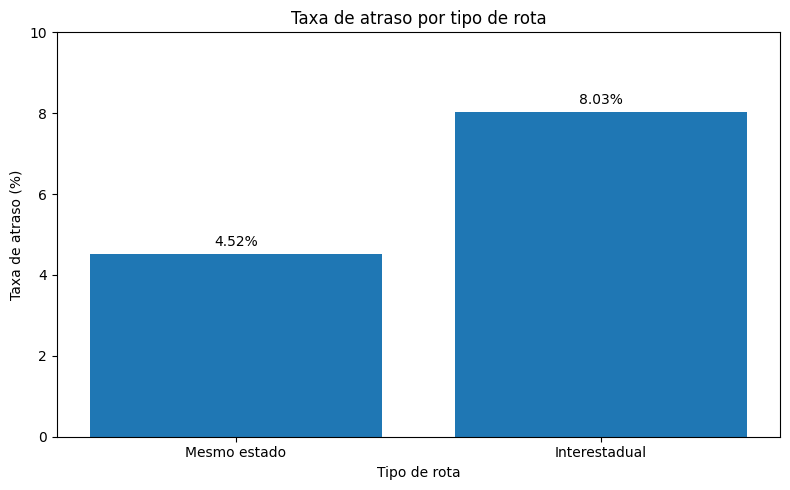

In [37]:

import matplotlib.pyplot as plt

# Gráfico de taxa de atraso por tipo de rota
plt.figure(figsize=(8, 5))

barras = plt.bar(
    analise_rotas["tipo_rota"],
    analise_rotas["taxa_atraso"]
)

plt.title("Taxa de atraso por tipo de rota")
plt.ylabel("Taxa de atraso (%)")
plt.xlabel("Tipo de rota")
plt.ylim(0, 10)

# Mostrar os percentuais sobre as barras
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 0.2,
        f"{altura:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


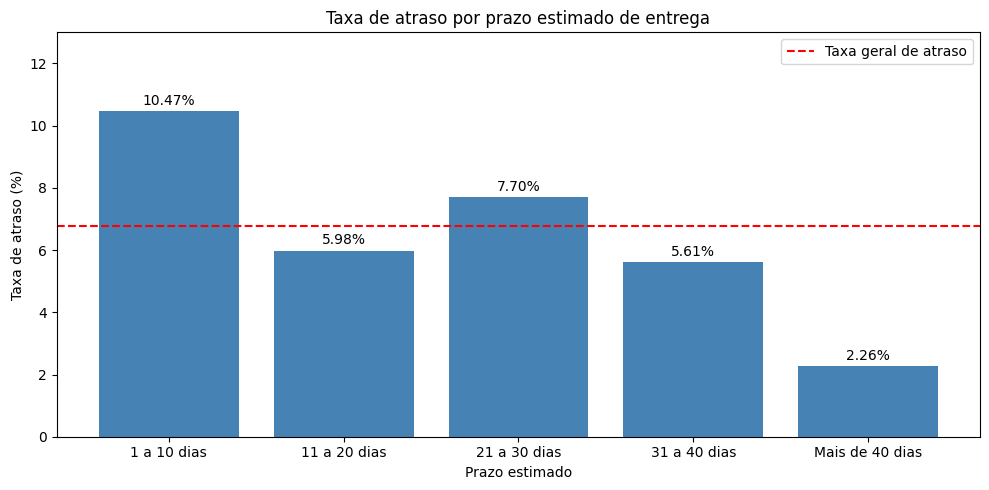

In [38]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

barras = plt.bar(
    analise_prazos["faixa_prazo"].astype(str),
    analise_prazos["taxa_atraso"],
    color="steelblue"
)

# Linha de referência: taxa geral de atraso
plt.axhline(
    y=df_modelo_final["atraso"].mean() * 100,
    color="red",
    linestyle="--",
    label="Taxa geral de atraso"
)

# Exibir valores sobre as barras
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 0.2,
        f"{altura:.2f}%",
        ha="center"
    )

plt.title("Taxa de atraso por prazo estimado de entrega")
plt.xlabel("Prazo estimado")
plt.ylabel("Taxa de atraso (%)")
plt.ylim(0, 13)
plt.legend()
plt.tight_layout()
plt.show()


**Interpretação dos resultados.** Na base analisada, pedidos com rota interestadual apresentaram taxa de atraso maior (8,03%) que pedidos com rota no mesmo estado (4,52%). Trata-se de associação observacional, não de efeito causal. As faixas de prazo também mostraram taxas diferentes.

**O que faremos e por quê:** Separar os pedidos por data de compra e usar apenas rótulos conhecidos até o corte de treinamento, evitando usar informação do futuro.

## 6. Separação temporal e prevenção de data leakage

In [39]:

# Verificar o período dos pedidos
print(
    "Primeira compra:",
    df_modelo_final["order_purchase_timestamp"].min()
)

print(
    "Última compra:",
    df_modelo_final["order_purchase_timestamp"].max()
)

# Quantidade de pedidos por ano
pedidos_por_ano = (
    df_modelo_final["order_purchase_timestamp"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("\nPedidos por ano:")
print(pedidos_por_ano)


Primeira compra: 2016-09-15 12:16:38
Última compra: 2018-08-29 15:00:37

Pedidos por ano:
order_purchase_timestamp
2016      267
2017    43426
2018    52777
Name: count, dtype: int64


In [40]:

# Ordenar os pedidos pela data da compra
df_ordenado = df_modelo_final.sort_values(
    by="order_purchase_timestamp"
).reset_index(drop=True)

# Conferir o período
print("Total de pedidos:", len(df_ordenado))

print(
    "Primeira compra:",
    df_ordenado["order_purchase_timestamp"].iloc[0]
)

print(
    "Última compra:",
    df_ordenado["order_purchase_timestamp"].iloc[-1]
)

# Visualizar os primeiros registros
display(
    df_ordenado[
        ["order_id", "order_purchase_timestamp", "atraso"]
    ].head()
)


Total de pedidos: 96470
Primeira compra: 2016-09-15 12:16:38
Última compra: 2018-08-29 15:00:37


,order_id,order_purchase_timestamp,atraso
0,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,1
1,3b697a20d9e427646d92567910af6d57,2016-10-03 09:44:50,0
2,be5bc2f0da14d8071e2d45451ad119d9,2016-10-03 16:56:50,0
3,a41c8759fbe7aab36ea07e038b2d4465,2016-10-03 21:13:36,0
4,d207cc272675637bfed0062edffd0818,2016-10-03 22:06:03,0


In [41]:

# Calcular posições das divisões
n = len(df_ordenado)

indice_treino = int(n * 0.60)
indice_validacao = int(n * 0.80)

# Identificar as datas correspondentes
data_treino = df_ordenado.loc[
    indice_treino, "order_purchase_timestamp"
]

data_validacao = df_ordenado.loc[
    indice_validacao, "order_purchase_timestamp"
]

print("Total de pedidos:", n)
print("Índice de 60%:", indice_treino)
print("Índice de 80%:", indice_validacao)

print("\nData aproximada do fim do treinamento:", data_treino)
print("Data aproximada do fim da validação:", data_validacao)


Total de pedidos: 96470
Índice de 60%: 57882
Índice de 80%: 77176

Data aproximada do fim do treinamento: 2018-03-03 10:08:51
Data aproximada do fim da validação: 2018-05-26 18:18:03


In [42]:

# Pedidos candidatos ao treinamento
pedidos_treino = df_ordenado.iloc[:indice_treino].copy()

# Verificar entregas posteriores ao limite temporal
entregas_futuras = (
    pedidos_treino["order_delivered_customer_date"]
    > data_treino
)

print("Pedidos candidatos ao treinamento:", len(pedidos_treino))

print(
    "Entregues após o limite:",
    entregas_futuras.sum()
)

print(
    "Entregues até o limite:",
    (~entregas_futuras).sum()
)

print(
    "Percentual de entregas posteriores:",
    round(entregas_futuras.mean() * 100, 2),
    "%"
)



Pedidos candidatos ao treinamento: 57882
Entregues após o limite: 3688
Entregues até o limite: 54194
Percentual de entregas posteriores: 6.37 %


In [43]:

# Selecionar pedidos do período de validação
pedidos_validacao = df_ordenado.iloc[
    indice_treino:indice_validacao
].copy()

# Verificar entregas até o corte da validação
validacao_disponivel = pedidos_validacao[
    pedidos_validacao["order_delivered_customer_date"]
    <= data_validacao
].copy()

# Identificar pedidos entregues posteriormente
validacao_pendente = pedidos_validacao[
    pedidos_validacao["order_delivered_customer_date"]
    > data_validacao
].copy()

# Conferir resultados
print("Pedidos candidatos:", len(pedidos_validacao))
print("Pedidos disponíveis:", len(validacao_disponivel))
print("Pedidos pendentes:", len(validacao_pendente))

print(
    "Total conferido:",
    len(validacao_disponivel) + len(validacao_pendente)
)

print(
    "Pedidos duplicados:",
    validacao_disponivel["order_id"].duplicated().sum()
)


Pedidos candidatos: 19294
Pedidos disponíveis: 17254
Pedidos pendentes: 2040
Total conferido: 19294
Pedidos duplicados: 0


In [44]:

# Selecionar os pedidos do período de teste
pedidos_teste = df_ordenado.iloc[
    indice_validacao:
].copy()

# Conferir quantidade e período
print("Pedidos de teste:", len(pedidos_teste))

print(
    "Primeira compra do teste:",
    pedidos_teste["order_purchase_timestamp"].min()
)

print(
    "Última compra do teste:",
    pedidos_teste["order_purchase_timestamp"].max()
)

# Verificar a última entrega registrada
print(
    "Última entrega do teste:",
    pedidos_teste["order_delivered_customer_date"].max()
)

# Verificar duplicações
print(
    "Pedidos duplicados:",
    pedidos_teste["order_id"].duplicated().sum()
)


Pedidos de teste: 19294
Primeira compra do teste: 2018-05-26 18:18:03
Última compra do teste: 2018-08-29 15:00:37
Última entrega do teste: 2018-10-17 13:22:46
Pedidos duplicados: 0


In [45]:

# Data de corte do treinamento
corte = data_treino

# Data de entrega e prazo prometido
data_entrega = pedidos_treino[
    "order_delivered_customer_date"
]

prazo_prometido = pedidos_treino[
    "order_estimated_delivery_date"
]

# Pedidos já entregues até o corte
ja_entregues = data_entrega <= corte

# Pedidos ainda não entregues cujo prazo já passou
prazo_vencido = (
    (~ja_entregues)
    & (prazo_prometido.dt.normalize() < corte.normalize())
)

# Pedidos com resultado conhecido
rotulo_conhecido = ja_entregues | prazo_vencido

print("Pedidos candidatos:", len(pedidos_treino))
print("Já entregues:", ja_entregues.sum())
print("Não entregues com prazo vencido:", prazo_vencido.sum())
print("Rótulos conhecidos:", rotulo_conhecido.sum())
print("Rótulos ainda desconhecidos:", (~rotulo_conhecido).sum())


Pedidos candidatos: 57882
Já entregues: 54194
Não entregues com prazo vencido: 140
Rótulos conhecidos: 54334
Rótulos ainda desconhecidos: 3548


In [46]:

# Criar conjunto de treinamento com rótulos conhecidos
df_treino = pedidos_treino.loc[
    rotulo_conhecido
].copy()

# Separar características e variável-alvo
X_treino = df_treino[variaveis_modelo].copy()
y_treino = df_treino["atraso"].copy()

# Validar resultados
print("Dimensão de X_treino:", X_treino.shape)
print("Dimensão de y_treino:", y_treino.shape)

print(
    "Pedidos duplicados:",
    df_treino["order_id"].duplicated().sum()
)

print(
    "Valores ausentes:",
    X_treino.isnull().sum().sum()
)

print("\nDistribuição da variável-alvo:")
print(y_treino.value_counts())

print("\nPercentual por classe:")
print(
    (y_treino.value_counts(normalize=True) * 100).round(2)
)


Dimensão de X_treino: (54334, 8)
Dimensão de y_treino: (54334,)
Pedidos duplicados: 0
Valores ausentes: 0

Distribuição da variável-alvo:
atraso
0    51451
1     2883
Name: count, dtype: int64

Percentual por classe:
atraso
0    94.69
1     5.31
Name: proportion, dtype: float64


In [47]:

# Criar uma tabela mensal para análise retrospectiva
analise_mensal = df_ordenado.copy()

analise_mensal["mes_compra"] = (
    analise_mensal["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Calcular indicadores mensais
atrasos_mensais = (
    analise_mensal
    .groupby("mes_compra")
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_atrasados=("atraso", "sum"),
        taxa_atraso=("atraso", "mean")
    )
    .reset_index()
)

atrasos_mensais["taxa_atraso"] = (
    atrasos_mensais["taxa_atraso"] * 100
).round(2)

display(atrasos_mensais)


,mes_compra,total_pedidos,pedidos_atrasados,taxa_atraso
0,2016-09,1,1,100.00
1,2016-10,265,2,0.75
2,2016-12,1,0,0.00
3,2017-01,750,22,2.93
4,2017-02,1653,49,2.96
5,2017-03,2546,116,4.56
6,2017-04,2303,151,6.56
7,2017-05,3545,106,2.99
8,2017-06,3135,95,3.03
9,2017-07,3872,108,2.79


In [48]:

import pandas as pd

# Definir janela de maturação
janela_dias = 30

# Data máxima de compra para o treinamento
limite_compra = data_treino - pd.Timedelta(
    days=janela_dias
)

# Selecionar pedidos comprados até esse limite
treino_maturado = pedidos_treino[
    pedidos_treino["order_purchase_timestamp"]
    <= limite_compra
].copy()

# Verificar quais rótulos já eram conhecidos
entregue_no_corte = (
    treino_maturado["order_delivered_customer_date"]
    <= data_treino
)

prazo_vencido_no_corte = (
    (~entregue_no_corte)
    & (
        treino_maturado["order_estimated_delivery_date"]
        .dt.normalize() < data_treino.normalize()
    )
)

rotulo_disponivel_maturado = (
    entregue_no_corte | prazo_vencido_no_corte
)

print("Limite de compra:", limite_compra)
print("Pedidos na janela maturada:", len(treino_maturado))
print(
    "Rótulos conhecidos:",
    rotulo_disponivel_maturado.sum()
)
print(
    "Rótulos desconhecidos:",
    (~rotulo_disponivel_maturado).sum()
)
print(
    "Percentual de rótulos conhecidos:",
    round(rotulo_disponivel_maturado.mean() * 100, 2),
    "%"
)


Limite de compra: 2018-02-01 10:08:51
Pedidos na janela maturada: 50800
Rótulos conhecidos: 50755
Rótulos desconhecidos: 45
Percentual de rótulos conhecidos: 99.91 %


In [49]:

# Selecionar apenas rótulos conhecidos no corte
df_treino_maturado = treino_maturado.loc[
    rotulo_disponivel_maturado
].copy()

# Separar características e variável-alvo
X_treino_maturado = df_treino_maturado[
    variaveis_modelo
].copy()

y_treino_maturado = df_treino_maturado[
    "atraso"
].copy()

# Verificar a base
print("Pedidos para treinamento:", len(df_treino_maturado))
print("Dimensão de X:", X_treino_maturado.shape)
print("Dimensão de y:", y_treino_maturado.shape)

print(
    "Pedidos duplicados:",
    df_treino_maturado["order_id"].duplicated().sum()
)

print(
    "Valores ausentes:",
    X_treino_maturado.isnull().sum().sum()
)

print("\nDistribuição das classes:")
print(y_treino_maturado.value_counts())

print("\nPercentual por classe:")
print(
    (y_treino_maturado.value_counts(normalize=True) * 100).round(2)
)


Pedidos para treinamento: 50755
Dimensão de X: (50755, 8)
Dimensão de y: (50755,)
Pedidos duplicados: 0
Valores ausentes: 0

Distribuição das classes:
atraso
0    47921
1     2834
Name: count, dtype: int64

Percentual por classe:
atraso
0    94.42
1     5.58
Name: proportion, dtype: float64


In [50]:

# Analisar atrasos por tipo de rota no treinamento

analise_rotas_treino = (
    df_treino_maturado
    .groupby("possui_rota_interestadual")
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_atrasados=("atraso", "sum"),
        taxa_atraso=("atraso", "mean")
    )
    .reset_index()
)

# Converter taxa para percentual
analise_rotas_treino["taxa_atraso"] = (
    analise_rotas_treino["taxa_atraso"] * 100
).round(2)

# Identificar os grupos
analise_rotas_treino["tipo_rota"] = (
    analise_rotas_treino["possui_rota_interestadual"]
    .map({
        False: "Mesmo estado",
        True: "Interestadual"
    })
)

display(
    analise_rotas_treino[
        [
            "tipo_rota",
            "total_pedidos",
            "pedidos_atrasados",
            "taxa_atraso"
        ]
    ]
)


,tipo_rota,total_pedidos,pedidos_atrasados,taxa_atraso
0,Mesmo estado,17025,634,3.72
1,Interestadual,33730,2200,6.52


**Critério temporal:** 60% dos pedidos mais antigos para o período de treinamento, 20% para validação e 20% para teste. No treinamento foi aplicada uma janela de maturação de 30 dias e filtrados os rótulos conhecidos no corte. O conjunto de teste permanece reservado até a avaliação final.

**Interpretação dos resultados.** A base final de treinamento maturado tem **50.755 pedidos**. A separação por tempo é mais realista do que embaralhar pedidos de períodos diferentes, mas não elimina por si só toda possibilidade de vazamento. A disponibilidade dos dados de vendedores e itens no instante da compra permanece uma hipótese documentada.

**O que faremos e por quê:** Preparar variáveis categóricas e numéricas, treinar os algoritmos e comparar modelos usando o mesmo conjunto temporal.

## 7. Modelagem

In [51]:
# Variável categórica e variáveis numéricas utilizadas pelos modelos
variaveis_categoricas = ["customer_state"]
variaveis_numericas = [
    "quantidade_itens", "valor_produtos", "valor_frete",
    "quantidade_vendedores", "possui_rota_interestadual",
    "quantidade_estados_origem", "prazo_estimado_dias"
]

In [52]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Pré-processamento atualizado
preprocessador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variaveis_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variaveis_numericas
        )
    ]
)

# Criar pipeline de Machine Learning
pipeline_modelo = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        (
            "modelo",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Pipeline criada com sucesso!")
print(pipeline_modelo)


Pipeline criada com sucesso!
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['customer_state']),
                                                 ('numericas', StandardScaler(),
                                                  ['quantidade_itens',
                                                   'valor_produtos',
                                                   'valor_frete',
                                                   'quantidade_vendedores',
                                                   'possui_rota_interestadual',
                                                   'quantidade_estados_origem',
                                                   'prazo_estimado_dias'])])),
                ('modelo',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
   

In [53]:

# Preparar conjunto de validação temporal

df_validacao = pedidos_validacao.copy()

# Separar características e variável-alvo
X_validacao = df_validacao[
    variaveis_modelo
].copy()

y_validacao = df_validacao[
    "atraso"
].copy()

# Conferir os dados
print("Dimensão de X_validacao:", X_validacao.shape)
print("Dimensão de y_validacao:", y_validacao.shape)

print(
    "Valores ausentes:",
    X_validacao.isnull().sum().sum()
)

print(
    "Pedidos duplicados:",
    df_validacao["order_id"].duplicated().sum()
)

print("\nDistribuição das classes:")
print(y_validacao.value_counts())

print("\nPercentual por classe:")
print(
    (y_validacao.value_counts(normalize=True) * 100).round(2)
)


Dimensão de X_validacao: (19294, 8)
Dimensão de y_validacao: (19294,)
Valores ausentes: 0
Pedidos duplicados: 0

Distribuição das classes:
atraso
0    17378
1     1916
Name: count, dtype: int64

Percentual por classe:
atraso
0    90.07
1     9.93
Name: proportion, dtype: float64


In [54]:

# Treinar o primeiro modelo FoodOps AI

pipeline_modelo.fit(
    X_treino_maturado,
    y_treino_maturado
)

print("Modelo treinado com sucesso!")

print(
    "Quantidade de pedidos utilizados:",
    len(X_treino_maturado)
)

print(
    "Quantidade de variáveis após pré-processamento:",
    pipeline_modelo.named_steps[
        "preprocessamento"
    ].get_feature_names_out().shape[0]
)

# Pontuações da Regressão Logística balanceada na validação.
y_prob = pipeline_modelo.predict_proba(X_validacao)[:, 1]


Modelo treinado com sucesso!
Quantidade de pedidos utilizados: 50755
Quantidade de variáveis após pré-processamento: 34


In [55]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Pré-processamento para Random Forest
preprocessador_rf = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variaveis_categoricas
        ),
        (
            "numericas",
            "passthrough",
            variaveis_numericas
        )
    ]
)

# Criar pipeline Random Forest
pipeline_rf = Pipeline(
    steps=[
        ("preprocessamento", preprocessador_rf),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=12,
                min_samples_leaf=10,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Pipeline Random Forest criada com sucesso!")
print(pipeline_rf)


Pipeline Random Forest criada com sucesso!
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['customer_state']),
                                                 ('numericas', 'passthrough',
                                                  ['quantidade_itens',
                                                   'valor_produtos',
                                                   'valor_frete',
                                                   'quantidade_vendedores',
                                                   'possui_rota_interestadual',
                                                   'quantidade_estados_origem',
                                                   'prazo_estimado_dias'])])),
                ('modelo',
                 RandomForestClassifier(class_weight='balanced', max

In [56]:

# Treinar o modelo Random Forest

pipeline_rf.fit(
    X_treino_maturado,
    y_treino_maturado
)

print("Random Forest treinado com sucesso!")

print(
    "Pedidos utilizados:",
    len(X_treino_maturado)
)

print(
    "Quantidade de árvores:",
    pipeline_rf.named_steps["modelo"].n_estimators
)

print(
    "Variáveis após pré-processamento:",
    len(
        pipeline_rf.named_steps[
            "preprocessamento"
        ].get_feature_names_out()
    )
)


Random Forest treinado com sucesso!
Pedidos utilizados: 50755
Quantidade de árvores: 200
Variáveis após pré-processamento: 34


In [57]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Previsões do Random Forest
y_pred_rf = pipeline_rf.predict(X_validacao)

# Pontuações de risco
y_prob_rf = pipeline_rf.predict_proba(
    X_validacao
)[:, 1]

# Calcular métricas
print("Resultados do Random Forest:\n")

print(
    f"Acurácia: {accuracy_score(y_validacao, y_pred_rf):.4f}"
)

print(
    f"Precision: {precision_score(y_validacao, y_pred_rf, zero_division=0):.4f}"
)

print(
    f"Recall: {recall_score(y_validacao, y_pred_rf, zero_division=0):.4f}"
)

print(
    f"F1-score: {f1_score(y_validacao, y_pred_rf, zero_division=0):.4f}"
)

print(
    f"ROC-AUC: {roc_auc_score(y_validacao, y_prob_rf):.4f}"
)

print(
    f"Average Precision: {average_precision_score(y_validacao, y_prob_rf):.4f}"
)

print("\nAlertas gerados:", y_pred_rf.sum())
print("Atrasos reais:", y_validacao.sum())


Resultados do Random Forest:

Acurácia: 0.7165
Precision: 0.1862
Recall: 0.5501
F1-score: 0.2782
ROC-AUC: 0.6729
Average Precision: 0.2005

Alertas gerados: 5662
Atrasos reais: 1916


In [58]:

import numpy as np
import pandas as pd

# Criar ranking de risco do Random Forest
ranking_rf = pd.DataFrame({
    "risco_previsto": y_prob_rf,
    "atraso_real": np.asarray(y_validacao)
})

# Ordenar por risco decrescente
ranking_rf = ranking_rf.sort_values(
    "risco_previsto",
    ascending=False
).reset_index(drop=True)

# Selecionar Top 10%
quantidade_top10_rf = int(
    np.ceil(len(ranking_rf) * 0.10)
)

top10_rf = ranking_rf.head(quantidade_top10_rf)

# Calcular indicadores
atrasos_top10_rf = int(
    top10_rf["atraso_real"].sum()
)

precision_top10_rf = (
    top10_rf["atraso_real"].mean()
)

recall_top10_rf = (
    atrasos_top10_rf /
    ranking_rf["atraso_real"].sum()
)

lift_top10_rf = (
    precision_top10_rf /
    ranking_rf["atraso_real"].mean()
)

print("Resultados Top 10% - Random Forest")
print("Pedidos priorizados:", len(top10_rf))
print("Atrasos identificados:", atrasos_top10_rf)
print(f"Precision@10%: {precision_top10_rf:.2%}")
print(f"Recall@10%: {recall_top10_rf:.2%}")
print(f"Lift@10%: {lift_top10_rf:.2f}x")


Resultados Top 10% - Random Forest
Pedidos priorizados: 1930
Atrasos identificados: 503
Precision@10%: 26.06%
Recall@10%: 26.25%
Lift@10%: 2.62x


In [59]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Calcular peso da classe minoritária
negativos = (y_treino_maturado == 0).sum()
positivos = (y_treino_maturado == 1).sum()

peso_positivo = negativos / positivos

print(f"Peso da classe positiva: {peso_positivo:.2f}")

# Pré-processamento
preprocessador_xgb = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variaveis_categoricas
        ),
        (
            "numericas",
            "passthrough",
            variaveis_numericas
        )
    ]
)

# Criar Pipeline XGBoost
pipeline_xgb = Pipeline(
    steps=[
        ("preprocessamento", preprocessador_xgb),
        (
            "modelo",
            XGBClassifier(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=peso_positivo,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

print("\nPipeline XGBoost criada com sucesso!")
print(pipeline_xgb)


Peso da classe positiva: 16.91

Pipeline XGBoost criada com sucesso!
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['customer_state']),
                                                 ('numericas', 'passthrough',
                                                  ['quantidade_itens',
                                                   'valor_produtos',
                                                   'valor_frete',
                                                   'quantidade_vendedores',
                                                   'possui_rota_interestadual',
                                                   'quantidade_estados_origem',
                                                   'prazo_estim

In [60]:

# Treinar o modelo XGBoost

pipeline_xgb.fit(
    X_treino_maturado,
    y_treino_maturado
)

print("XGBoost treinado com sucesso!")

print(
    "Pedidos utilizados:",
    len(X_treino_maturado)
)

print(
    "Quantidade de árvores:",
    pipeline_xgb.named_steps["modelo"].n_estimators
)

print(
    "Variáveis após pré-processamento:",
    len(
        pipeline_xgb.named_steps[
            "preprocessamento"
        ].get_feature_names_out()
    )
)


XGBoost treinado com sucesso!
Pedidos utilizados: 50755
Quantidade de árvores: 300
Variáveis após pré-processamento: 34


In [61]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Gerar previsões do XGBoost
y_pred_xgb = pipeline_xgb.predict(X_validacao)

# Obter pontuações de risco
y_prob_xgb = pipeline_xgb.predict_proba(
    X_validacao
)[:, 1]

# Calcular métricas
print("Resultados do XGBoost:\n")

print(
    f"Acurácia: {accuracy_score(y_validacao, y_pred_xgb):.4f}"
)

print(
    f"Precision: {precision_score(y_validacao, y_pred_xgb, zero_division=0):.4f}"
)

print(
    f"Recall: {recall_score(y_validacao, y_pred_xgb, zero_division=0):.4f}"
)

print(
    f"F1-score: {f1_score(y_validacao, y_pred_xgb, zero_division=0):.4f}"
)

print(
    f"ROC-AUC: {roc_auc_score(y_validacao, y_prob_xgb):.4f}"
)

print(
    f"Average Precision: {average_precision_score(y_validacao, y_prob_xgb):.4f}"
)

print("\nAlertas gerados:", int(y_pred_xgb.sum()))
print("Atrasos reais:", int(y_validacao.sum()))


Resultados do XGBoost:

Acurácia: 0.6978
Precision: 0.1739
Recall: 0.5449
F1-score: 0.2637
ROC-AUC: 0.6714
Average Precision: 0.1893

Alertas gerados: 6003
Atrasos reais: 1916


In [62]:

import numpy as np
import pandas as pd

# Criar ranking de risco do XGBoost
ranking_xgb = pd.DataFrame({
    "risco_previsto": y_prob_xgb,
    "atraso_real": np.asarray(y_validacao)
})

# Ordenar pedidos por risco
ranking_xgb = ranking_xgb.sort_values(
    "risco_previsto",
    ascending=False
).reset_index(drop=True)

# Selecionar os 10% com maior risco
quantidade_top10_xgb = int(
    np.ceil(len(ranking_xgb) * 0.10)
)

top10_xgb = ranking_xgb.head(
    quantidade_top10_xgb
)

# Calcular indicadores
atrasos_top10_xgb = int(
    top10_xgb["atraso_real"].sum()
)

precision_top10_xgb = (
    top10_xgb["atraso_real"].mean()
)

recall_top10_xgb = (
    atrasos_top10_xgb /
    ranking_xgb["atraso_real"].sum()
)

lift_top10_xgb = (
    precision_top10_xgb /
    ranking_xgb["atraso_real"].mean()
)

print("Resultados Top 10% - XGBoost")
print("Pedidos priorizados:", len(top10_xgb))
print("Atrasos identificados:", atrasos_top10_xgb)
print(f"Precision@10%: {precision_top10_xgb:.2%}")
print(f"Recall@10%: {recall_top10_xgb:.2%}")
print(f"Lift@10%: {lift_top10_xgb:.2f}x")


Resultados Top 10% - XGBoost
Pedidos priorizados: 1930
Atrasos identificados: 480
Precision@10%: 24.87%
Recall@10%: 25.05%
Lift@10%: 2.50x


**Experimento de sensibilidade:** a comparação a seguir remove `valor_produtos` apenas para investigar seu efeito. O modelo final continua usando as oito variáveis originais.


In [63]:

from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Criar conjuntos sem valor_produtos
X_treino_reduzido = X_treino_maturado.drop(
    columns=["valor_produtos"]
)

X_validacao_reduzido = X_validacao.drop(
    columns=["valor_produtos"]
)

# Criar novo pré-processador
variaveis_numericas_reduzidas = [
    coluna for coluna in variaveis_numericas
    if coluna != "valor_produtos"
]

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessador_reduzido = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variaveis_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variaveis_numericas_reduzidas
        )
    ]
)

pipeline_reduzida = Pipeline([
    ("preprocessamento", preprocessador_reduzido),
    (
        "modelo",
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        )
    )
])

# Treinar somente com os dados de treinamento
pipeline_reduzida.fit(
    X_treino_reduzido,
    y_treino_maturado
)

# Avaliar na validação
y_prob_reduzido = pipeline_reduzida.predict_proba(
    X_validacao_reduzido
)[:, 1]

print("Modelo original:")
print("ROC-AUC:", round(roc_auc_score(y_validacao, y_prob), 4))
print("AP:", round(average_precision_score(y_validacao, y_prob), 4))

print("\nModelo sem valor_produtos:")
print("ROC-AUC:", round(roc_auc_score(y_validacao, y_prob_reduzido), 4))
print("AP:", round(average_precision_score(y_validacao, y_prob_reduzido), 4))


Modelo original:
ROC-AUC: 0.6922
AP: 0.2036

Modelo sem valor_produtos:
ROC-AUC: 0.6928
AP: 0.2033


In [64]:

import numpy as np
import pandas as pd

def avaliar_top10(probabilidades, y_real):

    ranking = pd.DataFrame({
        "risco": probabilidades,
        "atraso": np.asarray(y_real)
    })

    ranking = ranking.sort_values(
        "risco",
        ascending=False
    )

    quantidade = int(np.ceil(len(ranking) * 0.10))
    top10 = ranking.head(quantidade)

    atrasos = int(top10["atraso"].sum())

    precision = atrasos / quantidade
    recall = atrasos / ranking["atraso"].sum()
    lift = precision / ranking["atraso"].mean()

    return {
        "Pedidos priorizados": quantidade,
        "Atrasos identificados": atrasos,
        "Precision@10%": round(precision * 100, 2),
        "Recall@10%": round(recall * 100, 2),
        "Lift@10%": round(lift, 2)
    }

comparacao = pd.DataFrame({
    "Original": avaliar_top10(y_prob, y_validacao),
    "Sem valor_produtos": avaliar_top10(
        y_prob_reduzido,
        y_validacao
    )
}).T

display(comparacao)


,Pedidos priorizados,Atrasos identificados,Precision@10%,Recall@10%,Lift@10%
Original,1930.0,549.0,28.45,28.65,2.86
Sem valor_produtos,1930.0,543.0,28.13,28.34,2.83


In [65]:

from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)
import numpy as np
import pandas as pd

# Criar uma cópia do modelo original
pipeline_sem_pesos = clone(pipeline_modelo)

# Remover ponderação das classes
pipeline_sem_pesos.set_params(
    modelo__class_weight=None
)

# Treinar com os mesmos dados
pipeline_sem_pesos.fit(
    X_treino_maturado,
    y_treino_maturado
)

# Gerar probabilidades na validação
y_prob_sem_pesos = pipeline_sem_pesos.predict_proba(
    X_validacao
)[:, 1]

# Comparar desempenho
comparacao_calibracao = pd.DataFrame({
    "Indicador": [
        "ROC-AUC",
        "Average Precision",
        "Brier Score",
        "Probabilidade média prevista",
        "Taxa real de atraso"
    ],
    "Modelo balanceado": [
        roc_auc_score(y_validacao, y_prob),
        average_precision_score(y_validacao, y_prob),
        brier_score_loss(y_validacao, y_prob),
        np.mean(y_prob),
        np.mean(y_validacao)
    ],
    "Modelo sem pesos": [
        roc_auc_score(y_validacao, y_prob_sem_pesos),
        average_precision_score(y_validacao, y_prob_sem_pesos),
        brier_score_loss(y_validacao, y_prob_sem_pesos),
        np.mean(y_prob_sem_pesos),
        np.mean(y_validacao)
    ]
})

display(comparacao_calibracao.round(4))


,Indicador,Modelo balanceado,Modelo sem pesos
0,ROC-AUC,0.6922,0.6956
1,Average Precision,0.2036,0.2094
2,Brier Score,0.2309,0.0875
3,Probabilidade média prevista,0.4743,0.0584
4,Taxa real de atraso,0.0993,0.0993


In [66]:

# Comparar a priorização dos dois modelos

comparacao_top10_pesos = pd.DataFrame({
    "Modelo balanceado": avaliar_top10(
        y_prob,
        y_validacao
    ),
    "Modelo sem pesos": avaliar_top10(
        y_prob_sem_pesos,
        y_validacao
    )
}).T

display(comparacao_top10_pesos)


,Pedidos priorizados,Atrasos identificados,Precision@10%,Recall@10%,Lift@10%
Modelo balanceado,1930.0,549.0,28.45,28.65,2.86
Modelo sem pesos,1930.0,561.0,29.07,29.28,2.93


**Interpretação dos resultados.** Foram comparados Regressão Logística balanceada, Random Forest, XGBoost e Regressão Logística sem pesos. A versão sem pesos foi selecionada na validação por melhor combinação de discriminação, precisão média e Brier Score; o teste final não foi usado para escolher o modelo.

**O que faremos e por quê:** Medir discriminação e capacidade de priorizar pedidos de alto risco no período de validação.

## 8. Avaliação

**Nota sobre as métricas:** a próxima célula apresenta o modelo **balanceado** (ROC-AUC 0,6922; AP 0,2036). A Regressão Logística **sem pesos**, escolhida na validação, obteve ROC-AUC 0,6956 e AP 0,2094. O teste final utiliza exclusivamente o modelo sem pesos.


In [67]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Obter pontuações do modelo para atraso
y_prob = pipeline_modelo.predict_proba(
    X_validacao
)[:, 1]

# Calcular métricas independentes do limiar
roc_auc = roc_auc_score(
    y_validacao, y_prob
)

average_precision = average_precision_score(
    y_validacao, y_prob
)

# Referência: frequência de atrasos
taxa_base = y_validacao.mean()

print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(average_precision, 4))
print("Taxa base de atraso:", round(taxa_base, 4))


ROC-AUC: 0.6922
Average Precision: 0.2036
Taxa base de atraso: 0.0993


In [68]:

import numpy as np
import pandas as pd

# Criar tabela de avaliação
ranking_risco = pd.DataFrame({
    "risco_previsto": y_prob,
    "atraso_real": np.asarray(y_validacao)
})

# Ordenar pela pontuação de risco
ranking_risco = ranking_risco.sort_values(
    "risco_previsto",
    ascending=False
).reset_index(drop=True)

# Selecionar os 10% com maior risco
quantidade_top10 = int(np.ceil(len(ranking_risco) * 0.10))

top10 = ranking_risco.head(quantidade_top10)

# Calcular indicadores
atrasos_top10 = int(top10["atraso_real"].sum())

precision_top10 = top10["atraso_real"].mean()

recall_top10 = (
    atrasos_top10 / ranking_risco["atraso_real"].sum()
)

lift_top10 = (
    precision_top10 / ranking_risco["atraso_real"].mean()
)

print("Pedidos no Top 10%:", len(top10))
print("Atrasos identificados:", atrasos_top10)
print(f"Precision@10%: {precision_top10:.2%}")
print(f"Recall@10%: {recall_top10:.2%}")
print(f"Lift@10%: {lift_top10:.2f}x")


Pedidos no Top 10%: 1930
Atrasos identificados: 549
Precision@10%: 28.45%
Recall@10%: 28.65%
Lift@10%: 2.86x


**Interpretação dos resultados.** Na validação, a Regressão Logística sem pesos obteve ROC-AUC **0,6956**, Average Precision **0,2094** e Brier Score **0,0875**. No Top 10%, identificou **561** atrasos em **1.930** pedidos (Precision@10% **29,07%**, Recall@10% **29,28%**, Lift **2,93×**). Esses números refletem uma taxa de atraso de **9,93%** nesse período.

**O que faremos e por quê:** Verificar se as probabilidades representam frequências reais de atraso e testar uma correção sem contaminar a avaliação posterior.

## 9. Calibração

In [69]:

# Recuperar os pedidos da janela de validação
df_janela_validacao = df_ordenado.iloc[
    indice_treino:indice_validacao
].copy()

# Garantir ordenação temporal
df_janela_validacao = (
    df_janela_validacao
    .sort_values("order_purchase_timestamp")
    .reset_index(drop=True)
)

# Identificar o ponto central
meio_validacao = len(df_janela_validacao) // 2

data_corte_calibracao = (
    df_janela_validacao.loc[
        meio_validacao,
        "order_purchase_timestamp"
    ]
)

print("Pedidos na janela:", len(df_janela_validacao))
print("Ponto central:", meio_validacao)
print("Data de corte:", data_corte_calibracao)

print(
    "Primeira compra:",
    df_janela_validacao[
        "order_purchase_timestamp"
    ].min()
)

print(
    "Última compra:",
    df_janela_validacao[
        "order_purchase_timestamp"
    ].max()
)


Pedidos na janela: 19294
Ponto central: 9647
Data de corte: 2018-04-15 20:17:11
Primeira compra: 2018-03-03 10:08:51
Última compra: 2018-05-26 18:16:57


In [70]:

import pandas as pd

# Selecionar primeira metade da validação
df_candidatos_calibracao = (
    df_janela_validacao.iloc[:meio_validacao].copy()
)

# Garantir formato datetime
colunas_datas = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in colunas_datas:
    df_candidatos_calibracao[coluna] = pd.to_datetime(
        df_candidatos_calibracao[coluna],
        errors="coerce"
    )

# Pedidos entregues até o corte
entregues = (
    df_candidatos_calibracao[
        "order_delivered_customer_date"
    ] <= data_corte_calibracao
)

# Pedidos ainda não entregues com prazo vencido
vencidos = (
    (
        df_candidatos_calibracao[
            "order_delivered_customer_date"
        ].isna()
        |
        (
            df_candidatos_calibracao[
                "order_delivered_customer_date"
            ] > data_corte_calibracao
        )
    )
    &
    (
        df_candidatos_calibracao[
            "order_estimated_delivery_date"
        ] < data_corte_calibracao
    )
)

# Rótulos disponíveis
rotulos_disponiveis_calibracao = entregues | vencidos

print(
    "Pedidos candidatos:",
    len(df_candidatos_calibracao)
)

print(
    "Entregues até o corte:",
    int(entregues.sum())
)

print(
    "Não entregues com prazo vencido:",
    int(vencidos.sum())
)

print(
    "Rótulos disponíveis:",
    int(rotulos_disponiveis_calibracao.sum())
)

print(
    "Rótulos desconhecidos:",
    int((~rotulos_disponiveis_calibracao).sum())
)


Pedidos candidatos: 9647
Entregues até o corte: 6703
Não entregues com prazo vencido: 332
Rótulos disponíveis: 7035
Rótulos desconhecidos: 2612


In [71]:

import numpy as np
import pandas as pd

# Selecionar somente pedidos com rótulos conhecidos
df_calibracao = df_candidatos_calibracao.loc[
    rotulos_disponiveis_calibracao
].copy()

# Identificar pedidos entregues até o corte
entregue_ate_corte = (
    df_calibracao["order_delivered_customer_date"]
    <= data_corte_calibracao
)

# Rótulo provisório do experimento original; corrigido na célula seguinte
df_calibracao["atraso_calibracao"] = np.where(
    entregue_ate_corte,
    (
        df_calibracao["order_delivered_customer_date"]
        >
        df_calibracao["order_estimated_delivery_date"]
    ).astype(int),
    1
)

print("Pedidos disponíveis:", len(df_calibracao))

print("\nDistribuição dos rótulos:")
print(
    df_calibracao["atraso_calibracao"].value_counts()
)

print("\nPercentual por classe:")
print(
    (
        df_calibracao["atraso_calibracao"]
        .value_counts(normalize=True) * 100
    ).round(2)
)

print(
    "\nPedidos duplicados:",
    df_calibracao["order_id"].duplicated().sum()
)


Pedidos disponíveis: 7035

Distribuição dos rótulos:
atraso_calibracao
0    5986
1    1049
Name: count, dtype: int64

Percentual por classe:
atraso_calibracao
0    85.09
1    14.91
Name: proportion, dtype: float64

Pedidos duplicados: 0


In [72]:

import numpy as np
import pandas as pd

# Comparar apenas os dias, ignorando horários
data_entrega = (
    df_calibracao["order_delivered_customer_date"]
    .dt.normalize()
)

data_estimada = (
    df_calibracao["order_estimated_delivery_date"]
    .dt.normalize()
)

# Identificar entregas conhecidas até o corte
entregue_ate_corte = (
    df_calibracao["order_delivered_customer_date"]
    <= data_corte_calibracao
)

# Corrigir rótulos
df_calibracao["atraso_calibracao"] = np.where(
    entregue_ate_corte,
    (data_entrega > data_estimada).astype(int),
    1
)

# Conferir resultados
comparacao_corrigida = pd.crosstab(
    df_calibracao["atraso"],
    df_calibracao["atraso_calibracao"]
)

display(comparacao_corrigida)

divergencias = (
    df_calibracao["atraso"]
    != df_calibracao["atraso_calibracao"]
).sum()

print("Pedidos analisados:", len(df_calibracao))
print("Classificações diferentes:", int(divergencias))

print("\nDistribuição corrigida:")
print(
    df_calibracao["atraso_calibracao"].value_counts()
)


atraso_calibracao,0,1
atraso,,
0,6104,0
1,0,931


Pedidos analisados: 7035
Classificações diferentes: 0

Distribuição corrigida:
atraso_calibracao
0    6104
1     931
Name: count, dtype: int64


In [73]:

# Verificar separação cronológica da calibração

ids_calibracao = set(df_calibracao["order_id"])

df_avaliacao_calibracao = (
    df_janela_validacao.iloc[meio_validacao:].copy()
)

ids_avaliacao = set(
    df_avaliacao_calibracao["order_id"]
)

print("Pedidos para calibração:", len(df_calibracao))

print(
    "Pedidos para avaliação:",
    len(df_avaliacao_calibracao)
)

print(
    "Pedidos em comum:",
    len(ids_calibracao & ids_avaliacao)
)

print(
    "Última compra da calibração:",
    df_calibracao["order_purchase_timestamp"].max()
)

print(
    "Primeira compra da avaliação:",
    df_avaliacao_calibracao[
        "order_purchase_timestamp"
    ].min()
)

print(
    "Separação temporal correta:",
    df_calibracao["order_purchase_timestamp"].max()
    <
    df_avaliacao_calibracao[
        "order_purchase_timestamp"
    ].min()
)


Pedidos para calibração: 7035
Pedidos para avaliação: 9647
Pedidos em comum: 0
Última compra da calibração: 2018-04-13 13:01:55
Primeira compra da avaliação: 2018-04-15 20:17:11
Separação temporal correta: True


In [74]:

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    brier_score_loss,
    average_precision_score,
    roc_auc_score
)

# Variáveis dos pedidos de calibração
X_calibracao = df_calibracao[
    X_treino_maturado.columns
].copy()

y_calibracao = (
    df_calibracao["atraso_calibracao"]
    .astype(int)
)

# Probabilidades do modelo já treinado
prob_calibracao = pipeline_sem_pesos.predict_proba(
    X_calibracao
)[:, 1]

# Evitar valores extremos no cálculo do logit
epsilon = 1e-6

prob_segura = np.clip(
    prob_calibracao,
    epsilon,
    1 - epsilon
)

# Transformar probabilidades em log-odds
logits_calibracao = np.log(
    prob_segura / (1 - prob_segura)
).reshape(-1, 1)

# Ajustar calibrador sigmoidal
calibrador_sigmoidal = LogisticRegression(
    C=1e6,
    max_iter=1000,
    random_state=42
)

calibrador_sigmoidal.fit(
    logits_calibracao,
    y_calibracao
)

print("Calibrador ajustado com sucesso!")
print("Pedidos utilizados:", len(X_calibracao))
print(
    "Taxa de atraso na calibração:",
    round(y_calibracao.mean() * 100, 2),
    "%"
)

print(
    "Coeficiente:",
    calibrador_sigmoidal.coef_[0][0]
)

print(
    "Intercepto:",
    calibrador_sigmoidal.intercept_[0]
)


Calibrador ajustado com sucesso!
Pedidos utilizados: 7035
Taxa de atraso na calibração: 13.23 %
Coeficiente: 1.2013317438447817
Intercepto: 1.4810050498808187


In [75]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    brier_score_loss,
    average_precision_score,
    roc_auc_score
)

# Variáveis da segunda metade da validação
X_avaliacao_calibracao = df_avaliacao_calibracao[
    X_treino_maturado.columns
].copy()

y_avaliacao_calibracao = (
    df_avaliacao_calibracao["atraso"].astype(int)
)

# Probabilidades originais
prob_original_avaliacao = (
    pipeline_sem_pesos.predict_proba(
        X_avaliacao_calibracao
    )[:, 1]
)

# Transformar em log-odds
prob_segura_avaliacao = np.clip(
    prob_original_avaliacao,
    1e-6,
    1 - 1e-6
)

logits_avaliacao = np.log(
    prob_segura_avaliacao /
    (1 - prob_segura_avaliacao)
).reshape(-1, 1)

# Aplicar calibrador já ajustado
prob_calibrada_avaliacao = (
    calibrador_sigmoidal.predict_proba(
        logits_avaliacao
    )[:, 1]
)

# Comparar métricas
comparacao_final_calibracao = pd.DataFrame({
    "Indicador": [
        "Brier Score",
        "Average Precision",
        "ROC-AUC",
        "Probabilidade média",
        "Taxa real de atraso"
    ],
    "Original": [
        brier_score_loss(
            y_avaliacao_calibracao,
            prob_original_avaliacao
        ),
        average_precision_score(
            y_avaliacao_calibracao,
            prob_original_avaliacao
        ),
        roc_auc_score(
            y_avaliacao_calibracao,
            prob_original_avaliacao
        ),
        np.mean(prob_original_avaliacao),
        np.mean(y_avaliacao_calibracao)
    ],
    "Calibrado": [
        brier_score_loss(
            y_avaliacao_calibracao,
            prob_calibrada_avaliacao
        ),
        average_precision_score(
            y_avaliacao_calibracao,
            prob_calibrada_avaliacao
        ),
        roc_auc_score(
            y_avaliacao_calibracao,
            prob_calibrada_avaliacao
        ),
        np.mean(prob_calibrada_avaliacao),
        np.mean(y_avaliacao_calibracao)
    ]
})

print("Pedidos avaliados:", len(y_avaliacao_calibracao))
display(comparacao_final_calibracao.round(4))


Pedidos avaliados: 9647


,Indicador,Original,Calibrado
0,Brier Score,0.0539,0.0609
1,Average Precision,0.1272,0.1272
2,ROC-AUC,0.6931,0.6931
3,Probabilidade média,0.0574,0.1311
4,Taxa real de atraso,0.0591,0.0591


**Interpretação dos resultados.** O calibrador sigmoidal foi ajustado em **7.035** pedidos com rótulos conhecidos da primeira metade da validação e avaliado na segunda metade. O Brier Score piorou de **0,0539** para **0,0609**; portanto, a correção foi **rejeitada**. A calibração permanece não resolvida: usar o escore para **ranking de risco**, não como probabilidade confiável de ocorrência.

**O que faremos e por quê:** Aplicar uma única vez o modelo escolhido aos pedidos futuros reservados e avaliar tanto as métricas gerais quanto o Top 10%.

## 10. Teste final

In [76]:

# Conferir variáveis do modelo final
print("Variáveis utilizadas no FoodOps AI:\n")

for i, coluna in enumerate(
    X_treino_maturado.columns,
    start=1
):
    print(f"{i}. {coluna}")

print("\nTotal de variáveis:", X_treino_maturado.shape[1])

print("\nColunas disponíveis na base principal:")
print(df_ordenado.columns.tolist())


Variáveis utilizadas no FoodOps AI:

1. customer_state
2. quantidade_itens
3. valor_produtos
4. valor_frete
5. quantidade_vendedores
6. possui_rota_interestadual
7. quantidade_estados_origem
8. prazo_estimado_dias

Total de variáveis: 8

Colunas disponíveis na base principal:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'atraso', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'quantidade_itens', 'valor_produtos', 'valor_frete', 'quantidade_vendedores', 'categoria_itens', 'possui_rota_interestadual', 'quantidade_estados_origem', 'prazo_estimado_dias', 'faixa_prazo']


In [77]:

# Auditoria das variáveis logísticas

colunas_auditoria = [
    "quantidade_itens",
    "quantidade_vendedores",
    "possui_rota_interestadual",
    "quantidade_estados_origem",
    "prazo_estimado_dias"
]

print("Valores ausentes:")
print(
    df_ordenado[colunas_auditoria]
    .isna()
    .sum()
)

print("\nEstatísticas das variáveis:")
display(
    df_ordenado[colunas_auditoria]
    .describe(include="all")
)

print("\nVerificação de consistência:")

print(
    "Pedidos com zero itens:",
    int((df_ordenado["quantidade_itens"] == 0).sum())
)

print(
    "Pedidos com zero vendedores:",
    int((df_ordenado["quantidade_vendedores"] == 0).sum())
)

print(
    "Pedidos com mais vendedores que itens:",
    int((
        df_ordenado["quantidade_vendedores"]
        > df_ordenado["quantidade_itens"]
    ).sum())
)

print(
    "Pedidos com mais estados de origem que vendedores:",
    int((
        df_ordenado["quantidade_estados_origem"]
        > df_ordenado["quantidade_vendedores"]
    ).sum())
)


Valores ausentes:
quantidade_itens             0
quantidade_vendedores        0
possui_rota_interestadual    0
quantidade_estados_origem    0
prazo_estimado_dias          0
dtype: int64

Estatísticas das variáveis:


,quantidade_itens,quantidade_vendedores,possui_rota_interestadual,quantidade_estados_origem,prazo_estimado_dias
count,96470.000000,96470.000000,96470,96470.000000,96470.000000
unique,NaN,NaN,2,NaN,NaN
top,NaN,NaN,True,NaN,NaN
freq,NaN,NaN,61895,NaN,NaN
mean,1.142210,1.013901,NaN,1.005349,24.372738
std,0.538824,0.123542,NaN,0.073928,8.758428
min,1.000000,1.000000,NaN,1.000000,3.000000
25%,1.000000,1.000000,NaN,1.000000,19.000000
50%,1.000000,1.000000,NaN,1.000000,24.000000
75%,1.000000,1.000000,NaN,1.000000,29.000000



Verificação de consistência:
Pedidos com zero itens: 0
Pedidos com zero vendedores: 0
Pedidos com mais vendedores que itens: 0
Pedidos com mais estados de origem que vendedores: 0


In [78]:

# Auditoria da correspondência entre itens e vendedores

auditoria_vendedores = df_itens[
    ["order_id", "seller_id"]
].merge(
    df_vendedores[
        ["seller_id", "seller_state"]
    ],
    on="seller_id",
    how="left",
    validate="many_to_one"
)

print("Total de itens:", len(df_itens))

print(
    "Itens após integração:",
    len(auditoria_vendedores)
)

print(
    "Vendedores sem estado:",
    auditoria_vendedores[
        "seller_state"
    ].isna().sum()
)

print(
    "Vendedores duplicados no cadastro:",
    df_vendedores["seller_id"].duplicated().sum()
)

print(
    "Estados de vendedores identificados:",
    auditoria_vendedores[
        "seller_state"
    ].nunique()
)


Total de itens: 112650
Itens após integração: 112650
Vendedores sem estado: 0
Vendedores duplicados no cadastro: 0
Estados de vendedores identificados: 23


In [79]:

import pandas as pd

# Recuperar estados dos vendedores por pedido
estados_por_pedido = (
    auditoria_vendedores
    .groupby("order_id")["seller_state"]
    .agg(lambda x: set(x))
)

# Base de auditoria
df_auditoria_rotas = df_ordenado[
    [
        "order_id",
        "customer_state",
        "possui_rota_interestadual",
        "quantidade_estados_origem",
        "quantidade_vendedores"
    ]
].copy()

# Associar estados dos vendedores
df_auditoria_rotas["estados_vendedores"] = (
    df_auditoria_rotas["order_id"]
    .map(estados_por_pedido)
)

# Reconstruir rota interestadual
df_auditoria_rotas["rota_recalculada"] = (
    df_auditoria_rotas.apply(
        lambda linha: any(
            estado != linha["customer_state"]
            for estado in linha["estados_vendedores"]
        ),
        axis=1
    )
)

# Reconstruir quantidade de estados
df_auditoria_rotas["estados_recalculados"] = (
    df_auditoria_rotas[
        "estados_vendedores"
    ].apply(len)
)

# Comparar resultados
divergencias_rotas = (
    df_auditoria_rotas["possui_rota_interestadual"]
    != df_auditoria_rotas["rota_recalculada"]
).sum()

divergencias_estados = (
    df_auditoria_rotas["quantidade_estados_origem"]
    != df_auditoria_rotas["estados_recalculados"]
).sum()

print("Pedidos analisados:", len(df_auditoria_rotas))

print(
    "Divergências nas rotas:",
    int(divergencias_rotas)
)

print(
    "Divergências nos estados de origem:",
    int(divergencias_estados)
)

print(
    "Pedidos sem informação de vendedores:",
    int(
        df_auditoria_rotas[
            "estados_vendedores"
        ].isna().sum()
    )
)


Pedidos analisados: 96470
Divergências nas rotas: 0
Divergências nos estados de origem: 0
Pedidos sem informação de vendedores: 0


In [80]:

import pandas as pd

# Recuperar conjunto de teste reservado
df_teste_final = df_ordenado.iloc[
    indice_validacao:
].copy()

# Data em que cada rótulo se torna conhecido
entrega = pd.to_datetime(
    df_teste_final["order_delivered_customer_date"],
    errors="coerce"
)

estimativa = pd.to_datetime(
    df_teste_final["order_estimated_delivery_date"],
    errors="coerce"
)

# Para pedidos atrasados, o atraso é conhecido
# a partir do dia seguinte ao prazo estimado
inicio_atraso = (
    estimativa.dt.normalize()
    + pd.Timedelta(days=1)
)

data_conhecimento = entrega.where(
    entrega.notna()
    & (
        entrega.dt.normalize()
        <= estimativa.dt.normalize()
    ),
    inicio_atraso
)

print("Pedidos de teste:", len(df_teste_final))

print(
    "Primeira compra:",
    df_teste_final["order_purchase_timestamp"].min()
)

print(
    "Última compra:",
    df_teste_final["order_purchase_timestamp"].max()
)

print(
    "Rótulos sem data de conhecimento:",
    int(data_conhecimento.isna().sum())
)

print(
    "Última data de conhecimento:",
    data_conhecimento.max()
)

print(
    "Pedidos duplicados:",
    int(df_teste_final["order_id"].duplicated().sum())
)

print(
    "Valores ausentes nas variáveis:",
    int(
        df_teste_final[
            X_treino_maturado.columns
        ].isna().sum().sum()
    )
)


Pedidos de teste: 19294
Primeira compra: 2018-05-26 18:18:03
Última compra: 2018-08-29 15:00:37
Rótulos sem data de conhecimento: 0
Última data de conhecimento: 2018-08-31 07:31:51
Pedidos duplicados: 0
Valores ausentes nas variáveis: 0


In [81]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# Preparar variáveis do teste
X_teste_final = df_teste_final[
    X_treino_maturado.columns
].copy()

y_teste_final = (
    df_teste_final["atraso"]
    .astype(int)
)

# Gerar probabilidades com o modelo já treinado
prob_teste_final = (
    pipeline_sem_pesos.predict_proba(
        X_teste_final
    )[:, 1]
)

# Avaliação final
print("AVALIAÇÃO FINAL - FOODOPS AI\n")

print("Pedidos avaliados:", len(y_teste_final))

print(
    "Taxa real de atraso:",
    round(y_teste_final.mean() * 100, 2),
    "%"
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_teste_final,
            prob_teste_final
        ),
        4
    )
)

print(
    "Average Precision:",
    round(
        average_precision_score(
            y_teste_final,
            prob_teste_final
        ),
        4
    )
)

print(
    "Brier Score:",
    round(
        brier_score_loss(
            y_teste_final,
            prob_teste_final
        ),
        4
    )
)

print(
    "Probabilidade média prevista:",
    round(prob_teste_final.mean() * 100, 2),
    "%"
)


AVALIAÇÃO FINAL - FOODOPS AI

Pedidos avaliados: 19294
Taxa real de atraso: 3.49 %
ROC-AUC: 0.7064
Average Precision: 0.0704
Brier Score: 0.0346
Probabilidade média prevista: 6.38 %


In [82]:

import numpy as np
import pandas as pd

# Ranking de risco no teste final
ranking_teste = pd.DataFrame({
    "risco_previsto": prob_teste_final,
    "atraso_real": np.asarray(y_teste_final)
})

ranking_teste = ranking_teste.sort_values(
    "risco_previsto",
    ascending=False
).reset_index(drop=True)

# Selecionar 10% dos pedidos
quantidade_top10 = int(
    np.ceil(len(ranking_teste) * 0.10)
)

top10_teste = ranking_teste.head(
    quantidade_top10
)

# Calcular indicadores
atrasos_identificados = int(
    top10_teste["atraso_real"].sum()
)

precision_top10 = (
    atrasos_identificados / quantidade_top10
)

recall_top10 = (
    atrasos_identificados /
    ranking_teste["atraso_real"].sum()
)

lift_top10 = (
    precision_top10 /
    ranking_teste["atraso_real"].mean()
)

print("FOODOPS AI - TESTE FINAL TOP 10%\n")

print("Pedidos priorizados:", quantidade_top10)
print("Atrasos identificados:", atrasos_identificados)
print(f"Precision@10%: {precision_top10:.2%}")
print(f"Recall@10%: {recall_top10:.2%}")
print(f"Lift@10%: {lift_top10:.2f}x")


FOODOPS AI - TESTE FINAL TOP 10%

Pedidos priorizados: 1930
Atrasos identificados: 138
Precision@10%: 7.15%
Recall@10%: 20.47%
Lift@10%: 2.05x


**Interpretação dos resultados.** Em **19.294** pedidos de teste, a taxa real de atraso foi **3,49%**; ROC-AUC **0,7064**, Average Precision **0,0704**, Brier Score **0,0346** e risco médio previsto **6,38%**. O Top 10% reuniu **1.930** pedidos e **138** atrasos: Precision@10% **7,15%**, Recall@10% **20,47%**, Lift **2,05×**.

**Comparação crítica:** embora o ROC-AUC tenha subido de 0,6956 para 0,7064, a **Average Precision caiu** de 0,2094 para 0,0704, e o Lift@10% caiu de 2,93× para 2,05×. Assim, o **desempenho operacional foi mais fraco no teste final do que na validação**. A taxa de atraso mudou de **9,93%** para **3,49%**, o que influencia métricas dependentes da prevalência. O risco médio previsto (6,38%) superestimou a frequência observada (3,49%).

**O que faremos e por quê:** Preparar um arquivo por pedido, com risco, resultado observado e prioridade, para visualizar os resultados históricos em um dashboard.

## 11. Exportação para o Power BI

In [83]:

# Criar base operacional para o dashboard
df_dashboard = df_teste_final[
    [
        "order_id",
        "order_purchase_timestamp",
        "customer_state",
        "prazo_estimado_dias",
        "possui_rota_interestadual"
    ]
].copy().reset_index(drop=True)

# Adicionar previsões e resultados
df_dashboard["risco_previsto"] = prob_teste_final

df_dashboard["atraso_real"] = (
    np.asarray(y_teste_final)
)

# Classificar os 10% de maior risco
df_dashboard["prioridade"] = "Normal"

indices_top10 = (
    df_dashboard["risco_previsto"]
    .nlargest(quantidade_top10)
    .index
)

df_dashboard.loc[
    indices_top10, "prioridade"
] = "Alta"

# Conferência
print("Dimensão:", df_dashboard.shape)

print("\nDistribuição de prioridades:")
print(df_dashboard["prioridade"].value_counts())

print("\nPrévia:")
display(df_dashboard.head())


Dimensão: (19294, 8)

Distribuição de prioridades:
prioridade
Normal    17364
Alta       1930
Name: count, dtype: int64

Prévia:


,order_id,order_purchase_timestamp,customer_state,prazo_estimado_dias,possui_rota_interestadual,risco_previsto,atraso_real,prioridade
0,88a78af246c6c2db88e72b384796c98c,2018-05-26 18:18:03,SP,25,False,0.025267,0,Normal
1,d7c663de1470a2d3671791d3f093991c,2018-05-26 18:25:53,SP,33,False,0.016648,0,Normal
2,c0e57db4a4a6ef32aa28911d1c07df81,2018-05-26 18:41:31,SP,34,False,0.015691,0,Normal
3,4007c8123697940f0574798a18c6ad29,2018-05-26 18:50:39,MG,39,True,0.013559,0,Normal
4,ce0fc5f1ff91f6aaf5eae637a2827b2e,2018-05-26 18:51:09,SP,33,False,0.016791,0,Normal


In [84]:

from google.colab import files

# Exportar base operacional
nome_arquivo = "foodops_ai_dashboard.csv"

df_dashboard.to_csv(
    nome_arquivo,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo criado:", nome_arquivo)
print("Linhas exportadas:", len(df_dashboard))
print("Colunas exportadas:", len(df_dashboard.columns))

# Baixar para o computador
files.download(nome_arquivo)


Arquivo criado: foodops_ai_dashboard.csv
Linhas exportadas: 19294
Colunas exportadas: 8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Interpretação dos resultados.** O CSV exportado contém **19.294 pedidos**, com **1.930** marcados como prioridade alta. Trata-se de uma demonstração retrospectiva com resultados reais conhecidos, não de um painel em tempo real.

**O que faremos e por quê:** Explicitar o que o estudo demonstra, o que ainda não foi validado e como o protótipo pode evoluir.

## 12. Limitações e próximos passos

- **Mudança de prevalência:** a taxa de atrasos caiu de 9,93% na validação para 3,49% no teste; a precisão média e a concentração no Top 10% também diminuíram.
- **Calibração não resolvida:** o ajuste sigmoidal piorou o Brier Score. O escore deve ser interpretado como **ordenação relativa**, não como probabilidade bem calibrada.
- **Cobertura limitada:** o Top 10% identifica 20,47% dos atrasos; a maioria continua fora do grupo priorizado.
- **Viés de seleção:** foram analisados pedidos entregues; resultados podem não generalizar para pedidos ainda em andamento, cancelados ou nunca entregues.
- **Disponibilidade no instante da compra:** a consistência geográfica foi auditada, mas a disponibilidade temporal de todos os atributos de vendedores e itens não foi comprovada integralmente.
- **Próximos passos:** salvar o pipeline e as versões das dependências; documentar as origens dos dados; testar o pipeline com novos pedidos; criar o dashboard no Power BI; estudar monitoramento de drift, novos períodos e integração com SQL/IA. Não reajustar o modelo usando o conjunto de teste final.

**O que faremos e por quê:** Reunir em um único lugar o problema, os dados, o método, os resultados e as principais limitações para quem visita o portfólio.

## 13. Resumo do projeto

| Item | Resumo |
|---|---|
| **Problema** | Priorizar pedidos com maior risco de atraso de entrega. |
| **Dados** | Olist; 96.470 pedidos entregues após preparação; dados de clientes, itens e vendedores. |
| **Método** | Limpeza, integração, engenharia de atributos, divisão temporal 60/20/20, maturação dos rótulos, Regressão Logística, Random Forest e XGBoost. |
| **Modelo selecionado** | Regressão Logística sem pesos, escolhida na validação. |
| **Teste final** | 19.294 pedidos; ROC-AUC 0,7064; AP 0,0704; Brier 0,0346. |
| **Priorização** | Top 10%: 1.930 pedidos, 138 atrasos, Precision 7,15%, Recall 20,47%, Lift 2,05×. |
| **Limitações** | Queda de desempenho operacional frente à validação; mudança da taxa de atraso; probabilidades não calibradas; análise restrita a pedidos entregues. |

**Conclusão:** o FoodOps AI demonstrou capacidade moderada de **ordenar pedidos por risco** e concentrar atrasos em um grupo de acompanhamento prioritário. É um protótipo analítico para portfólio, **não** um sistema de previsão calibrado ou pronto para produção.